# Getting started: plate properties for CLPT, FSDT and TSDT

This tutorial creates laminates with `laminated_plate` and `isotropic_plate`
and inspects the matrices used by the classical laminated plate theory
(CLPT), the first-order shear deformation theory (FSDT) and the third-order
shear deformation theory (TSDT), the equivalent properties, the effect of an
offset of the reference surface, and the moments of the density used in mass
matrices. SI units are used throughout.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from composites import laminated_plate, isotropic_plate

np.set_printoptions(precision=4, suppress=False, linewidth=100)

# E11, E22, nu12, G12, G13, G23 of a CFRP ply
laminaprop = (142e9, 8.7e9, 0.28, 5.1e9, 5.1e9, 3.2e9)
rho = 1600. # kg/m^3
plyt = 0.125e-3 # m

## A quasi-isotropic laminate

The stacking sequence is given from the bottom to the top ply. `ABD` is the
6x6 matrix of the CLPT and of the FSDT, relating $\{N_{xx}, N_{yy}, N_{xy},
M_{xx}, M_{yy}, M_{xy}\}$ to the membrane strains and curvatures of the
reference surface.

In [2]:
qi = laminated_plate([0, 45, -45, 90, 90, -45, 45, 0], plyt=plyt,
                     laminaprop=laminaprop, rho=rho)
print('h =', qi.h)
print('A =\n', qi.A)
print('B =\n', qi.B)
print('D =\n', qi.D)

h = 0.001
A =
 [[5.9947e+07 1.8214e+07 0.0000e+00]
 [1.8214e+07 5.9947e+07 1.8626e-09]
 [0.0000e+00 1.8626e-09 2.0866e+07]]
B =
 [[ 0.0000e+00  8.5265e-14  0.0000e+00]
 [ 8.5265e-14  0.0000e+00  0.0000e+00]
 [ 0.0000e+00  0.0000e+00 -2.8422e-13]]
D =
 [[8.3812 1.2715 0.5232]
 [1.2715 2.1027 0.5232]
 [0.5232 0.5232 1.4925]]


`B` is zero for this symmetric laminate, up to round-off. `A` is isotropic, $A_{11} =
A_{22}$, $A_{66} = (A_{11} - A_{12})/2$ and $A_{16} = A_{26} = 0$, whereas
`D` is not: the $\pm 45$ plies give $D_{16}$ and $D_{26}$.

## FSDT: transverse shear stiffness

`Ats` contains the shear correction, by default with the equilibrium
approach `'rohwer'`, and it is used as it is in an FSDT model. `Abar_ts` is
the uncorrected constant-strain stiffness. `scf_k13` and `scf_k23` are the
ratios between them, informative only.

In [3]:
print('Ats =\n', qi.Ats)
print('Abar_ts =\n', qi.Abar_ts)
print('scf_k13 = %.4f, scf_k23 = %.4f' % (qi.scf_k13, qi.scf_k23))

Ats =
 [[2948931.4831   43511.7955]
 [  43511.7955 3247625.5097]]
Abar_ts =
 [[4.1500e+06 2.9104e-11]
 [2.9104e-11 4.1500e+06]]
scf_k13 = 0.7826, scf_k23 = 0.7106


## TSDT: higher-order matrices

The TSDT uses as well `E`, `F`, `H`, the integrals of the ply stiffnesses
times $z^3$, $z^4$, $z^6$, and the uncorrected transverse shear matrices
`Abar_ts`, `Dts`, `Fts`, integrals times $1$, $z^2$, $z^4$. As `B`, the
odd integral `E` is zero for a symmetric laminate, up to round-off.

In [4]:
for name in ('E', 'F', 'H', 'Dts', 'Fts'):
    print(name, '=\n', getattr(qi, name))

E =
 [[0.0000e+00 1.0164e-20 0.0000e+00]
 [1.0164e-20 1.3553e-20 0.0000e+00]
 [0.0000e+00 0.0000e+00 6.7763e-21]]
F =
 [[1.4909e-06 1.2375e-07 7.3577e-08]
 [1.2375e-07 2.1560e-07 7.3577e-08]
 [7.3577e-08 7.3577e-08 1.5690e-07]]
H =
 [[2.8914e-13 1.4855e-14 8.8139e-15]
 [1.4855e-14 3.0086e-14 8.8139e-15]
 [8.8139e-15 8.8139e-15 2.0775e-14]]
Dts =
 [[0.3013 0.0148]
 [0.0148 0.3904]]
Fts =
 [[4.2830e-08 2.0874e-09]
 [2.0874e-09 6.0920e-08]]


## Equivalent properties and the isotropic plate

The equivalent membrane moduli follow from the inverse of `ABD`. An
isotropic plate with these moduli and the same thickness has the same `A`,
but not the same `D`, because the bending stiffness depends on the position
of the plies through the thickness.

In [5]:
print('e1 = %.4g, e2 = %.4g, g12 = %.4g, nu12 = %.4f'
      % (qi.e1, qi.e2, qi.g12, qi.nu12))
iso = isotropic_plate(thickness=qi.h, E=qi.e1, nu=qi.nu12, rho=rho)
print('A, max relative difference:',
      np.abs(iso.A - qi.A).max()/np.abs(qi.A).max())
print('D11 laminate / D11 isotropic: %.4f' % (qi.D11/iso.D11))
print('D22 laminate / D22 isotropic: %.4f' % (qi.D22/iso.D22))

e1 = 5.441e+10, e2 = 5.441e+10, g12 = 2.087e+10, nu12 = 0.3038
A, max relative difference: 2.485714270108366e-16
D11 laminate / D11 isotropic: 1.6777
D22 laminate / D22 isotropic: 0.4209


## An unsymmetric laminate

A cross-ply with two plies couples membrane and bending, `B` $\neq 0$, and
the odd integral `E` is no longer zero.

In [6]:
cp = laminated_plate([0, 90], plyt=plyt, laminaprop=laminaprop, rho=rho)
print('B =\n', cp.B)
print('E =\n', cp.E)

B =
 [[-1.0464e+03  0.0000e+00  1.8684e-15]
 [ 0.0000e+00  1.0464e+03  6.2207e-14]
 [ 1.8684e-15  6.2207e-14  0.0000e+00]]
E =
 [[-8.1753e-06  0.0000e+00  1.4597e-23]
 [ 0.0000e+00  8.1753e-06  4.8599e-22]
 [ 1.4597e-23  4.8599e-22  0.0000e+00]]


## Effect of the offset

`offset` is the position of the mid-surface relative to the reference
surface. For an isotropic plate the closed form is $B = d h C$ and $D = h
(d^2 + h^2/12) C$, with $d$ the offset: $B$ grows linearly and $D$
quadratically with the offset, while $A$ and `Ats` do not change.

A55 constant: True


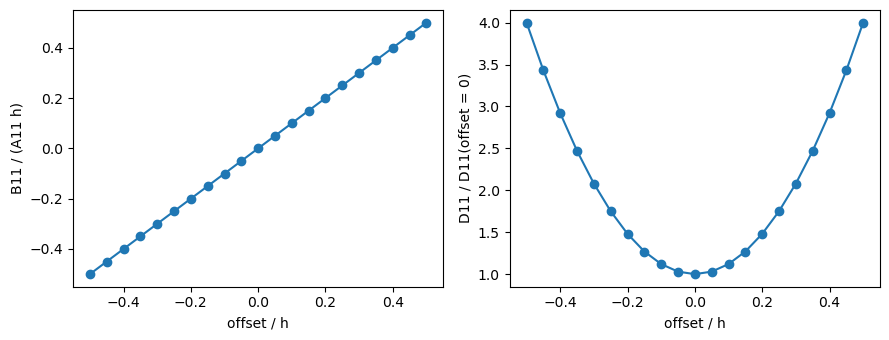

In [7]:
h = 2e-3
offsets = np.linspace(-h/2, h/2, 21)
B11, D11, A55 = [], [], []
for d in offsets:
    lam = isotropic_plate(thickness=h, E=70e9, nu=0.3, offset=d, rho=2700.)
    B11.append(lam.B11)
    D11.append(lam.D11)
    A55.append(lam.A55)
lam0 = isotropic_plate(thickness=h, E=70e9, nu=0.3, rho=2700.)

fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
ax[0].plot(offsets/h, np.array(B11)/(lam0.A11*h), 'o-')
ax[0].set_xlabel('offset / h')
ax[0].set_ylabel('B11 / (A11 h)')
ax[1].plot(offsets/h, np.array(D11)/lam0.D11, 'o-')
ax[1].set_xlabel('offset / h')
ax[1].set_ylabel('D11 / D11(offset = 0)')
fig.tight_layout()
print('A55 constant:', np.allclose(A55, lam0.A55, rtol=1e-12))

## Moments of the density

The mass matrices use the moments $I_n = \int \rho z^n dz$: `intrho`,
`intrhoz`, `intrhoz2` for the CLPT and the FSDT, and also `intrhoz3`,
`intrhoz4`, `intrhoz6` for the TSDT. Without offset the odd moments of a
homogeneous plate vanish; with an offset $d$, $I_1 = \rho h d$ and $I_2 =
\rho h (d^2 + h^2/12)$.

In [8]:
names = ('intrho', 'intrhoz', 'intrhoz2', 'intrhoz3', 'intrhoz4', 'intrhoz6')
d = 0.5e-3
for lam, label in ((lam0, 'offset = 0'),
                   (isotropic_plate(thickness=h, E=70e9, nu=0.3, offset=d,
                                    rho=2700.), 'offset = %g' % d)):
    print(label)
    for name in names:
        print('    %-9s = % .6e' % (name, getattr(lam, name)))
print('rho h d                  = % .6e' % (2700.*h*d))
print('rho h (d^2 + h^2/12)     = % .6e' % (2700.*h*(d**2 + h**2/12)))

offset = 0
    intrho    =  5.400000e+00
    intrhoz   =  0.000000e+00
    intrhoz2  =  1.800000e-06
    intrhoz3  =  0.000000e+00
    intrhoz4  =  1.080000e-12
    intrhoz6  =  7.714286e-19
offset = 0.0005
    intrho    =  5.400000e+00
    intrhoz   =  2.700000e-03
    intrhoz2  =  3.150000e-06
    intrhoz3  =  3.375000e-09
    intrhoz4  =  4.117500e-12
    intrhoz6  =  6.593304e-18
rho h d                  =  2.700000e-03
rho h (d^2 + h^2/12)     =  3.150000e-06


With different densities per ply, e.g. a sandwich with a light core, the
argument `rhos` of `laminated_plate` gives one density per ply.

In [9]:
face = laminaprop
core = (0.1e9, 0.1e9, 0.3, 0.04e9, 0.04e9, 0.04e9)
sw = laminated_plate([0, 90, 0, 0, 90, 0], plyts=[plyt, plyt, 5e-3, 5e-3,
                     plyt, plyt],
                     laminaprops=[face, face, core, core, face, face],
                     rhos=[rho, rho, 50., 50., rho, rho])
print('mass per unit area: %.4f kg/m^2' % sw.intrho)
for name in names:
    print('%-9s = % .6e' % (name, getattr(sw, name)))

mass per unit area: 1.3000 kg/m^2
intrho    =  1.300000e+00
intrhoz   =  0.000000e+00
intrhoz2  =  2.518333e-05
intrhoz3  =  6.617445e-24
intrhoz4  =  6.150631e-10
intrhoz6  =  1.565537e-14
